# NARS Alone vs. LLM (Direct) vs. LLM (CoT) vs. NARS + LLM
Every system reads the same 70B-extracted facts. Set the dataset, split, hops and sample size in **Settings**.

1. **Run NARS**: translates facts into triples and rules, executes ONA, and extracts ONA's `Stamp=[...]` symbolic proof chain and candidate bindings (`nars.jsonl`).
2. **Run Baselines — LLM Direct**: every model answers directly from the extracted facts (`baselines.jsonl`).
3. **Run Baselines — LLM CoT**: every model reasons step-by-step (Chain-of-Thought) across the facts before outputting `Answer: <short answer>` (`cot.jsonl`).
4. **Run NARS + LLM**: every model answers using its initial reasoning **plus** NARS's verified symbolic proof trace (`nars_llm.jsonl`).
5. **Final Report**: compares **NARS Alone**, **LLM (Direct)**, **LLM (CoT)**, and **NARS + LLM** across all three metrics (`Exact`, `Lenient`, `Judge`) and saves `report_nars_llm.png`.

In [1]:
# ── Settings: change these, then run the cells you need ──────────────────────────────────────────
import importlib
import json
import os
import pickle
import random
import re
import threading
import time
import unicodedata
import urllib.request
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from openai import OpenAI
from prettytable import PrettyTable

import ONA

importlib.reload(ONA)  # pick up edits to ONA.py without restarting

from keys import deepinfra_key
API_KEY = deepinfra_key()  # $DEEPINFRA_API_KEY or the git-ignored .deepinfra_key
DATASET = "MuSiQue"   # "MuSiQue", "HotpotQA" or "2Wiki"
SPLIT = "test"        # "dev" for the pilot, "test" for the full 100q existing runs
HOPS = 2              # MuSiQue has 2, 3 and 4 hops; HotpotQA and 2Wiki only 2
N_QUESTIONS = 100     # 100q existing runs (or 15 on "dev" for the pilot)
DISTRACTORS = False   # True: every system reads the facts of ALL paragraphs (supporting + distractors)
SEED = 0              # same seed -> same questions every run
WORKERS = 8           # questions processed at the same time
ONA_PATH = "/Users/mina/Developer/OpenNARS-for-Applications/NAR"
JUDGE_MODEL = "Qwen/Qwen2.5-72B-Instruct"  # for the judge metric; not one of the systems, so nobody grades itself
NARS_MODEL = "deepseek-ai/DeepSeek-V3"     # turns the facts into triples and rules for ONA
ONA_OPTIONS = {"plan": True, "votes": 3, "merge_relations": True}

BASELINES = [  # evaluated both ALONE and WITH NARS symbolic proof trace; small to large
    "google/gemma-3-4b-it",
    "meta-llama/Meta-Llama-3.1-8B-Instruct-Turbo",
    "mistralai/Mistral-Nemo-Instruct-2407",               # 12B
    "google/gemma-3-12b-it",
    "microsoft/phi-4",                                    # 14B
    "mistralai/Mistral-Small-3.2-24B-Instruct-2506",
    "google/gemma-3-27b-it",
    "google/gemma-4-31B-it",
    "meta-llama/Llama-3.3-70B-Instruct-Turbo",
    "Qwen/Qwen3-Next-80B-A3B-Instruct",
    "Qwen/Qwen3-235B-A22B-Instruct-2507",
    "deepseek-ai/DeepSeek-V3",
]

client = OpenAI(api_key=API_KEY, base_url="https://api.deepinfra.com/v1/openai", max_retries=2, timeout=60)


def check_models(models):
    """DeepInfra silently answers retired models with another one (Llama-3.2-1B came back as gemma-4-31B).
    One tiny request per model; stop if any model is served under another name."""
    def served(m):
        try:
            return client.chat.completions.create(model=m, max_tokens=1, messages=[{"role": "user", "content": "Hi"}]).model
        except Exception as error:
            return f"error: {type(error).__name__}"
    with ThreadPoolExecutor(8) as executor:
        swapped = {m: s for m, s in zip(models, executor.map(served, models)) if s != m}
    assert not swapped, f"These models are not served as requested: {swapped}"


check_models([NARS_MODEL, JUDGE_MODEL, *BASELINES])


def label(model):
    return model.split("/")[-1].replace("Meta-", "").replace("-Instruct-Turbo", "").replace("-Instruct", "").replace("-it", "")


def load_prices():
    """Live DeepInfra prices, USD per million tokens (input, output). Tries 3 times; {} if all fail."""
    for attempt in range(3):
        try:
            with urllib.request.urlopen("https://api.deepinfra.com/models/list", timeout=20) as response:
                return {m["model_name"]: (m["pricing"]["cents_per_input_token"] * 1e4, m["pricing"]["cents_per_output_token"] * 1e4)
                        for m in json.load(response) if (m.get("pricing") or {}).get("type") == "tokens"}
        except Exception as error:
            print(f"Price lookup failed ({type(error).__name__}), attempt {attempt + 1}/3")
            time.sleep(2)
    return {}


PRICES = load_prices()


def cost(input_tokens, output_tokens, model):
    if model not in PRICES:
        PRICES.update(load_prices())
    if model not in PRICES:
        print(f"   ! no price for {model}: its cost counts as $0")
        PRICES[model] = (0, 0)
    price = PRICES[model]
    return (input_tokens * price[0] + output_tokens * price[1]) / 1_000_000


for m in [NARS_MODEL, JUDGE_MODEL, *BASELINES]:
    if m not in PRICES:
        print(f"Warning: no price for {m}; costs will be $0 until the lookup works.")


# ── Scoring ──────────────────────────────────────────────────────────────────────────────────────
def normalize(text):
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().casefold()
    return re.sub(r"[^a-z0-9]", "", re.sub(r"\b(a|an|the)\b", " ", text))


def lenient(answer, golds):
    """Answer and a gold answer contain each other, the shorter covering at least half of the longer."""
    a = normalize(answer or "")
    for g in map(normalize, golds):
        short, long_ = sorted((a, g), key=len)
        if short and short in long_ and 2 * len(short) >= len(long_):
            return True
    return False


def exact(answer, golds):
    return any(normalize(answer or "") == normalize(g) for g in golds)


JUDGE_PROMPT = """You grade answers to a question. Be strict.

Question: {question}
Gold answer: {gold}
Model answer: {answer}

The model answer is correct ONLY if it names the same entity, date, number or place as the gold answer.
Different wording, a full name, or extra detail around the same thing is fine:
  "Philip Mountbatten" for "Prince Philip" -> yes
  "12,000 people" for "12,000" -> yes
  "4 June 1990" for "1990" -> yes
It is WRONG if it names something else, even something related: a part of the gold answer, a larger thing that
contains it, a person connected to it, or a vaguer or partial answer:
  "Battle of Hastings" for "Norman Conquest" -> no   (a part, not the same thing)
  "Henry VIII" for "Edward VI" -> no                 (a related person)
  "Europe" for "France" -> no                        (broader)
  "200 km" for "200 km south of Paris" -> no         (partial)
  "The text does not say" -> no                      (no answer)
Reply with only yes or no."""


METRICS = ["exact", "lenient", "judge"]


def metrics(q, answer):
    """The three accuracy metrics for one answer."""
    g = golds(q)
    result = {"exact": exact(answer, g), "lenient": lenient(answer, g), "judge_cost": 0.0}
    result["judge"] = result["lenient"]
    if answer and not result["lenient"]:
        try:
            response = client.chat.completions.create(model=JUDGE_MODEL, temperature=0, max_tokens=3, messages=[{
                "role": "user", "content": JUDGE_PROMPT.format(question=q["question"], gold=q["answer"], answer=answer)}])
            result["judge"] = (response.choices[0].message.content or "").strip().lower().startswith("yes")
            result["judge_cost"] = cost(response.usage.prompt_tokens or 0, response.usage.completion_tokens or 0, JUDGE_MODEL)
        except Exception as error:
            print(f"   ! judge failed ({type(error).__name__}), using the lenient match")
    return result


def so_far(records):
    return "  ".join(f"{m[0].upper()} {sum(r[m] for r in records)}" for m in METRICS)


def mentions(text, golds):
    t = normalize(text)
    heads = [re.split(r"[,(]", g)[0] for g in golds]
    return any(g and t and (g in t or (t in g and 2 * len(t) >= len(g))) for g in map(normalize, [*golds, *heads]))


def golds(q):
    return [q["answer"], *(q.get("gold_answers") or [])]


def paragraphs(q):
    return [p for p in (q["context"] if DISTRACTORS else q["supporting"]) if p["facts"]]


def facts(q):
    return [f for p in paragraphs(q) for f in p["facts"]]


STOPWORDS = {"the", "and", "for", "with", "who", "what", "which", "when", "where", "was", "did", "does", "from", "film"}


def normalize_words(text):
    return unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower().replace("_", " ")


def from_question(rules, question):
    q_words = set(re.findall(r"[a-z0-9]{3,}", normalize_words(question))) - STOPWORDS
    for rule in rules:
        constants = [x for c in rule["conditions"] for x in (c[0], c[2]) if not x.startswith("?")]
        if not constants or not all(set(re.findall(r"[a-z0-9]{3,}", normalize_words(x))) & q_words for x in constants):
            return False
    return bool(rules)


# ── Questions, run folder and the shared run loop ────────────────────────────────────────────────
with open(f"runs/{DATASET}_{SPLIT}_entity.pkl", "rb") as f:
    questions = pickle.load(f)
pool = [i for i, q in enumerate(questions) if q["hops"] == HOPS]
INDICES = sorted(random.Random(SEED).sample(pool, min(N_QUESTIONS, len(pool))))
OPTIONS_TAG = "_".join(k if v is True else f"{k}{v}" for k, v in ONA_OPTIONS.items()
                       if v is True or (type(v) is int and v > 1))
RUN_DIR = (f"runs/{DATASET}{'_dev' if SPLIT == 'dev' else ''}_{HOPS}hop_{len(INDICES)}q_seed{SEED}"
           + (f"_{OPTIONS_TAG}" if OPTIONS_TAG else "") + ("_distractors" if DISTRACTORS else ""))
missing = [i for i in INDICES if DISTRACTORS and "context" not in questions[i]]
assert not missing, (f"{len(missing)} questions have no distractor facts: run  python pipeline.py --dataset {DATASET} "
                     f"--split {SPLIT} --hops {HOPS} --distractors {N_QUESTIONS}")
os.makedirs(RUN_DIR, exist_ok=True)


def run_all(task, out_file, show):
    """Run task(index) on every question in parallel. Each record is saved and printed as soon as it finishes."""
    path, records, start = f"{RUN_DIR}/{out_file}", [], time.time()
    if os.path.exists(path):
        cached = [json.loads(line) for line in open(path) if line.strip()]
        if {r["index"] for r in cached} == set(INDICES):
            for done, record in enumerate(cached, 1):
                records.append(record)
                print(f"[{done:>3}/{len(INDICES)}, {len(INDICES) - done:>3} left] Q{record['index']:<4} gold: {record['gold'][:30]}"
                      f"\n      {show(record, records)}"
                      f"\n      spent ${sum(r['cost'] + r['judge_cost'] for r in records):.4f}   cached")
            return sorted(records, key=lambda r: r["index"])
    open(path, "w").close()
    with ThreadPoolExecutor(WORKERS) as executor:
        futures = [executor.submit(task, i) for i in INDICES]
        for done, future in enumerate(as_completed(futures), 1):
            record = future.result()
            records.append(record)
            with open(path, "a") as f:
                f.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")
            print(f"[{done:>3}/{len(INDICES)}, {len(INDICES) - done:>3} left] Q{record['index']:<4} gold: {record['gold'][:30]}"
                  f"\n      {show(record, records)}"
                  f"\n      spent ${sum(r['cost'] + r['judge_cost'] for r in records):.4f}   {time.time() - start:.0f}s")
    return sorted(records, key=lambda r: r["index"])


print(f"{len(INDICES)} random {DATASET} {SPLIT} {HOPS}-hop questions (of {len(pool)}). ONA options: {ONA_OPTIONS}. "
      f"Results go to {RUN_DIR}/")

100 random MuSiQue test 2-hop questions (of 140). ONA options: {'plan': True, 'votes': 3, 'merge_relations': True}. Results go to runs/MuSiQue_2hop_100q_seed0_plan_votes3_merge_relations/


## Run NARS
Runs standalone NARS (`nars.jsonl`) and extracts the formal `Stamp=[...]` symbolic proof trace (matched triples, variable bindings, and derived candidate with NARS truth values `{f, c}`) so NARS can guide the LLMs in the next step.

In [2]:
# ── NARS Alone + Symbolic Proof Trace Extraction ─────────────────────────────────────────────────
def extract_nars_trace(ona, answer):
    """Extract ONA's Stamp=[...] evidential proof triples, rule variable bindings, and truth values."""
    output = ona.last_output or ""
    names = ona.names or {}
    aliases_of = {}
    for alt, canon in (ona.aliases or {}).items():
        if alt != canon:
            aliases_of.setdefault(canon, []).append(alt)

    def fmt_ent(atom_or_name):
        disp = names.get(atom_or_name, atom_or_name)
        alts = aliases_of.get(disp)
        return f"{disp} (also called: {', '.join(alts[:2])})" if alts else disp

    # 1. Parse ONA's input Stamp IDs -> readable triples
    stamp_triples = {}
    for s, o, r, sid in re.findall(
        r"^Input:\s*<\((\S+)\s*\*\s*(\S+)\)\s*-->\s*(\S+)>\.[^\n]*Stamp=\[(\d+)\]", output, flags=re.M
    ):
        stamp_triples[sid] = f"{fmt_ent(s)} | {ONA.relation_name(r)} | {fmt_ent(o)}"

    # 2. Parse ONA's Answer lines -> Stamp IDs and Truth (frequency, confidence)
    proof_lines, best_f, best_c = [], None, None
    for term, stamp_str, f_val, c_val in re.findall(
        r"^Answer:\s*<(\S+)\s*-->\s*answer>\.[^\n]*Stamp=\[([0-9,]+)\]\s*Truth:\s*frequency=([\d.]+),\s*confidence=([\d.]+)",
        output, flags=re.M
    ):
        if answer and ONA.atom(answer) == term or best_c is None or float(c_val) > best_c:
            best_f, best_c = float(f_val), float(c_val)
            for sid in stamp_str.split(","):
                if sid in stamp_triples and stamp_triples[sid] not in proof_lines:
                    proof_lines.append(stamp_triples[sid])

    # 3. Also extract full variable bindings along the rule hops (catches cases where a rule returned ?A instead of ?B)
    binding_chains = []
    if ona.last_triples and ona.last_rules:
        fact_set = {(ONA.atom(t["subject"]), ONA.atom(t["relation"]), ONA.atom(t["object"])) for t in ona.last_triples}
        for rule in ona.last_rules:
            for binding, used_facts in ona._bindings(rule["conditions"], fact_set, return_used=True):
                for fs, fr, fo in used_facts:
                    line = f"{fmt_ent(fs)} | {ONA.relation_name(fr)} | {fmt_ent(fo)}"
                    if line not in proof_lines:
                        proof_lines.append(line)
                chain = ", ".join(f"{v} = {fmt_ent(val)}" for v, val in sorted(binding.items()))
                if chain and chain not in binding_chains:
                    binding_chains.append(chain)

    parts = []
    if ona.plan_text:
        parts.append("Hop plan:\n" + "\n".join(f"  {line}" for line in ona.plan_text.splitlines()))
    if proof_lines:
        parts.append("Matched proof triples (ONA Stamp):\n" + "\n".join(f"  - {line}" for line in proof_lines[:8]))
    if binding_chains:
        parts.append("Variable bindings:\n" + "\n".join(f"  - {c}" for c in binding_chains[:4]))
    cands = [fmt_ent(c) for c in (ona.candidates or [])]
    votes = [v for v in [s.get("answer") for s in (ona.samples or [])] if v]
    if answer:
        truth_str = f" (frequency={best_f:.2f}, confidence={best_c:.2f})" if best_c is not None else ""
        parts.append(f"NARS derived answer: {answer}{truth_str}")
        if len(cands) > 1:
            parts.append(f"Other candidates bound by rules: {', '.join(cands[:5])}")
        if len(set(votes)) > 1:
            parts.append(f"Rule vote answers: {', '.join(votes)}")
    else:
        parts.append("NARS derived answer: None (no complete rule chain matched; derive the answer from the facts).")
    return "\n".join(parts)


def lost_at(q, ona, answer, correct):
    g = golds(q)
    if correct:
        return "correct"
    if not any(mentions(f, g) for f in facts(q)):
        return "lost in facts"
    if not ona.last_triples:
        return "API error"
    if not any(mentions(x, g) for t in ona.last_triples for x in (t["subject"], t["object"])):
        return "lost in triples"
    if not ona.last_rules:
        return "no valid rule"
    if not any(mentions(ona.names.get(c, c), g) for c in ona.candidates):
        return "rules miss the answer"
    return "ONA did not derive it" if answer is None else "picked wrong answer"


def run_nars(index):
    q = questions[index]
    ona = ONA.OnaReasoner(client, model=NARS_MODEL, **ONA_OPTIONS)
    answer, error = None, None
    try:
        answer = ona.solve([p["facts"] for p in paragraphs(q)], q["question"], ONA_PATH)
    except Exception as e:
        error = f"{type(e).__name__}: {e}"
        print(f"   ! Q{index}: {str(e)[:80]}")
    m = metrics(q, answer)
    trace_text = extract_nars_trace(ona, answer)
    return {"index": index, "question": q["question"], "gold": q["answer"], "answer": answer, **m,
            "lost_at": lost_at(q, ona, answer, m["judge"]), "rules": ona.last_rules,
            "auto_repairs": dict(ona.auto_repairs), "from_question": from_question(ona.last_rules, q["question"]),
            "ona_top": ona.ona_top, "ona_top_lenient": lenient(ona.ona_top, golds(q)),
            "votes": [s["answer"] for s in ona.samples], "trace_text": trace_text,
            "cost": cost(ona.usage["input_tokens"], ona.usage["output_tokens"], NARS_MODEL)}


def show_nars(r, records):
    why = "" if r["judge"] else f"   ({r['lost_at']})"
    return (f"NARS {'✓' if r['judge'] else '✗'} {(r['answer'] or '-')[:30]}{why}"
            f"   so far ({len(records)}): {so_far(records)}")


nars = run_all(run_nars, "nars.jsonl", show_nars)
n = len(nars)
print(f"\nNARS ALONE on {n} {DATASET} {SPLIT} {HOPS}-hop questions, ONA options {ONA_OPTIONS}   cost ${sum(r['cost'] for r in nars):.4f}"
      f" + judge ${sum(r['judge_cost'] for r in nars):.4f}")
for m in METRICS:
    print(f"   {m:<8} {sum(r[m] for r in nars)}/{n} = {100 * sum(r[m] for r in nars) / n:.1f}%")

[  1/100,  99 left] Q15   gold: Benny Beaver
      NARS ✓ Benny Beaver   so far (1): E 1  L 1  J 1
      spent $0.0008   cached
[  2/100,  98 left] Q19   gold: 2005
      NARS ✓ 2005   so far (2): E 2  L 2  J 2
      spent $0.0016   cached
[  3/100,  97 left] Q0    gold: Hayneville
      NARS ✗ Lowndes County   (rules miss the answer)   so far (3): E 2  L 2  J 2
      spent $0.0025   cached
[  4/100,  96 left] Q3    gold: Rohana Wijeweera
      NARS ✓ Rohana Wijeweera   so far (4): E 3  L 3  J 3
      spent $0.0034   cached
[  5/100,  95 left] Q2    gold: PowerShare
      NARS ✓ PowerShare   so far (5): E 4  L 4  J 4
      spent $0.0042   cached
[  6/100,  94 left] Q14   gold: 207.77 million people
      NARS ✓ 207.77 million people   so far (6): E 5  L 5  J 5
      spent $0.0055   cached
[  7/100,  93 left] Q9    gold: Johan Remkes
      NARS ✓ Johan Remkes   so far (7): E 6  L 6  J 6
      spent $0.0070   cached
[  8/100,  92 left] Q32   gold: U.S. Marshal Rooster Cogburn
      NARS 

## Run the baselines (LLM Alone)

In [3]:
# ── Baselines (LLM Alone): every model answers from the same extracted facts NARS gets ───────────
PROMPT = """Answer the question using only the facts below. Return only the short answer, without explanation.

Facts:
{facts}

Question: {question}
Answer:"""


def ask(q, model):
    answer, tokens = None, (0, 0)
    try:
        response = client.chat.completions.create(
            model=model, temperature=0, max_tokens=64, messages=[{"role": "user", "content": PROMPT.format(
                facts="\n".join(f"- {f}" for f in facts(q)), question=q["question"])}])
        answer = (response.choices[0].message.content or "").strip().split("\n")[0]
        tokens = (response.usage.prompt_tokens or 0, response.usage.completion_tokens or 0)
    except Exception as error:
        print(f"   ! Q{q['id'][:8]} {label(model)}: {type(error).__name__}")
    return {"answer": answer, **metrics(q, answer), "cost": cost(*tokens, model)}


def run_baselines(index):
    q = questions[index]
    answers = {label(m): ask(q, m) for m in BASELINES}
    return {"index": index, "question": q["question"], "gold": q["answer"], "answers": answers,
            "cost": sum(a["cost"] for a in answers.values()),
            "judge_cost": sum(a["judge_cost"] for a in answers.values())}


def show_baselines(r, records):
    return "  ".join(f"{name} {'✓' if a['judge'] else '✗'} {sum(x['answers'][name]['judge'] for x in records)}"
                     for name, a in r["answers"].items()) + "   (judge metric)"


baselines = run_all(run_baselines, "baselines.jsonl", show_baselines)

n = len(baselines)
table = PrettyTable(["Model (LLM Alone)", "Exact", "Lenient", "Judge", "Cost USD"])
for m in BASELINES:
    answers = [r["answers"][label(m)] for r in baselines]
    table.add_row([label(m), *[f"{100 * sum(a[k] for a in answers) / n:.1f}%" for k in METRICS],
                   f"${sum(a['cost'] for a in answers):.4f}"])
print(f"\nLLM ALONE on {n} {DATASET} {HOPS}-hop questions (from the extracted facts)"
      f"   judge ${sum(r['judge_cost'] for r in baselines):.4f}")
print(table)

[  1/100,  99 left] Q15   gold: Benny Beaver
      gemma-3-4b ✓ 1  Llama-3.1-8B ✓ 1  Mistral-Nemo-2407 ✓ 1  gemma-3-12b ✓ 1  phi-4 ✓ 1  Mistral-Small-3.2-24B-2506 ✓ 1  gemma-3-27b ✓ 1  gemma-4-31B ✓ 1  Llama-3.3-70B ✓ 1  Qwen3-Next-80B-A3B ✓ 1  Qwen3-235B-A22B-2507 ✓ 1  DeepSeek-V3 ✓ 1  GLM-5.3-Flash ✓ 1   (judge metric)
      spent $0.0003   cached
[  2/100,  98 left] Q3    gold: Rohana Wijeweera
      gemma-3-4b ✓ 2  Llama-3.1-8B ✓ 2  Mistral-Nemo-2407 ✓ 2  gemma-3-12b ✓ 2  phi-4 ✓ 2  Mistral-Small-3.2-24B-2506 ✓ 2  gemma-3-27b ✓ 2  gemma-4-31B ✓ 2  Llama-3.3-70B ✓ 2  Qwen3-Next-80B-A3B ✓ 2  Qwen3-235B-A22B-2507 ✓ 2  DeepSeek-V3 ✓ 2  GLM-5.3-Flash ✓ 2   (judge metric)
      spent $0.0009   cached
[  3/100,  97 left] Q19   gold: 2005
      gemma-3-4b ✓ 3  Llama-3.1-8B ✓ 3  Mistral-Nemo-2407 ✓ 3  gemma-3-12b ✓ 3  phi-4 ✓ 3  Mistral-Small-3.2-24B-2506 ✓ 3  gemma-3-27b ✓ 3  gemma-4-31B ✓ 3  Llama-3.3-70B ✓ 3  Qwen3-Next-80B-A3B ✓ 3  Qwen3-235B-A22B-2507 ✓ 3  DeepSeek-V3 ✓ 3  GLM-5.3-Flas

## Run Baselines (LLM Chain-of-Thought)
Every model reasons step-by-step across the extracted facts before outputting `Answer: <short answer>` (`cot.jsonl`).

In [ ]:
# ── Chain-of-Thought Baselines: step-by-step reasoning from the same extracted facts ───────────────
COT_PROMPT = """Answer the question using only the facts below.
Think step by step in 1-2 short sentences to connect the facts, then on the final line write "Answer: " followed by only the short answer.

Facts:
{facts}

Question: {question}"""


def parse_cot_answer(text):
    if not text:
        return None
    lines = [ln.strip() for ln in text.strip().splitlines() if ln.strip()]
    if not lines:
        return None
    for ln in reversed(lines):
        m = re.search(r"(?:final\s+)?answer\s*[:\-]\s*(.+)$", ln, re.I)
        if m:
            ans = m.group(1).strip().strip("*\"'`").rstrip(".")
            if ans:
                return ans
    return lines[-1].strip("*\"'`").rstrip(".")


def ask_cot(q, model):
    answer, raw, tokens = None, None, (0, 0)
    try:
        response = client.chat.completions.create(
            model=model, temperature=0, max_tokens=160, messages=[{"role": "user", "content": COT_PROMPT.format(
                facts="\n".join(f"- {f}" for f in facts(q)), question=q["question"])}])
        raw = (response.choices[0].message.content or "").strip()
        answer = parse_cot_answer(raw)
        tokens = (response.usage.prompt_tokens or 0, response.usage.completion_tokens or 0)
    except Exception as error:
        print(f"   ! Q{q['id'][:8]} CoT {label(model)}: {type(error).__name__}")
    return {"answer": answer, "cot_trace": raw, **metrics(q, answer), "cost": cost(*tokens, model)}


def run_cot(index):
    q = questions[index]
    answers = {label(m): ask_cot(q, m) for m in BASELINES}
    return {"index": index, "question": q["question"], "gold": q["answer"], "answers": answers,
            "cost": sum(a["cost"] for a in answers.values()),
            "judge_cost": sum(a["judge_cost"] for a in answers.values())}


def show_cot(r, records):
    return "  ".join(f"{name} {'✓' if a['judge'] else '✗'} {sum(x['answers'][name]['judge'] for x in records)}"
                     for name, a in r["answers"].items()) + "   (CoT judge)"


cot_baselines = run_all(run_cot, "cot.jsonl", show_cot)

n = len(cot_baselines)
table = PrettyTable(["Model (LLM CoT)", "Exact", "Lenient", "Judge", "Cost USD"])
for m in BASELINES:
    answers = [r["answers"][label(m)] for r in cot_baselines]
    table.add_row([f"{label(m)} (CoT)", *[f"{100 * sum(a[k] for a in answers) / n:.1f}%" for k in METRICS],
                   f"${sum(a['cost'] for a in answers):.4f}"])
print(f"\nLLM (CoT) on {n} {DATASET} {HOPS}-hop questions (from the extracted facts)"
      f"   judge ${sum(r['judge_cost'] for r in cot_baselines):.4f}")
print(table)

## Run NARS + LLM (NARS helping each LLM)
Every model receives the same extracted facts **plus** NARS's symbolic proof trace (`Stamp=[...]` matched triples, variable bindings, and derived candidate). The LLM acts as the result interpreter and fallback reasoner.

In [4]:
# ── NARS + LLM: Symbolic Verification & Guided Refinement (inspired by Logic-LM, Pan et al., 2023) ──
NARS_LLM_PROMPT = """Answer the question using only the facts, your initial draft answer, and the NARS symbolic reasoning trace below.
- The NARS trace provides a candidate multi-hop chain of triples and variable bindings matched by a symbolic reasoner.
- Verify your initial draft answer against the NARS trace and the facts:
  1. If your initial draft answer is a full sentence that already identifies the same entity/value derived by NARS, return only that concise short answer.
  2. If your initial draft said the facts do not contain the answer, dropped the unit of measurement, or stopped at the Hop-1 bridge entity connecting the paragraphs, follow the NARS proof chain to give the final Hop-2 answer.
  3. If the NARS rule matched a different relation than what the question asks, keep the true answer from the facts.
- Return only the short answer, without explanation.

Facts:
{facts}

Your Initial Draft Answer:
{draft}

NARS Symbolic Trace:
{trace}

Question: {question}
Answer:"""

nars_by_index = {r["index"]: r for r in map(json.loads, open(f"{RUN_DIR}/nars.jsonl"))} if os.path.exists(f"{RUN_DIR}/nars.jsonl") else {}
baselines_by_index = {r["index"]: r for r in map(json.loads, open(f"{RUN_DIR}/baselines.jsonl"))} if os.path.exists(f"{RUN_DIR}/baselines.jsonl") else {}
assert nars_by_index, "Run the NARS cell first so nars.jsonl is available."

ABSTAIN_RE = re.compile(
    r"\b(not contain|no information|not mention|not state|not provide|cannot|can't|don't have|do not have|"
    r"unknown|none|no answer|not specified|does not say|unable to|misunderstanding|not include|no role)\b",
    re.I,
)
NEG_Q_RE = re.compile(r"\b(not|never|neither|except|besides|other than)\b", re.I)


def in_para(ans, p_facts_str):
    na, np_ = normalize(ans), normalize(p_facts_str)
    return bool(na and na in np_)


def valid_rule_shape(rule):
    conds = rule.get("conditions") or []
    ans_var = rule.get("answer")
    if not (2 <= len(conds) <= 3):
        return False
    vars_all = {x for c in conds for x in (c[0], c[2]) if x.startswith("?")}
    if len(vars_all) < 2:
        return False
    if ans_var in (conds[0][0], conds[0][2]) and ans_var not in (conds[-1][0], conds[-1][2]):
        return False
    counts = Counter(x for c in conds for x in (c[0], c[2]) if x.startswith("?"))
    if any(c[0].startswith("?") and c[2].startswith("?") and any(counts[v] == 1 and v != ans_var for v in (c[0], c[2])) for c in conds[1:]):
        return False
    return True


def has_valid_nars_chain(r, q):
    """100% symbolic verification of NARS's derivation (rule shape, vote consensus, and multi-paragraph bridge topology)."""
    question = q["question"]
    ans = r.get("answer")
    rules = r.get("rules") or []
    votes = r.get("votes") or []
    repairs = r.get("auto_repairs") or {}
    if not ans or not rules:
        return False
    if NEG_Q_RE.search(question):
        return False
    if None in votes or len([v for v in votes if v]) < 2 or len(set(votes)) > 1:
        return False
    if r.get("ona_top") and normalize(r["ona_top"]) != normalize(ans):
        return False
    if repairs.get("pruned_unlinked") or repairs.get("inverse_relation"):
        return False
    if not all(valid_rule_shape(rule) for rule in rules):
        return False
    ps = paragraphs(q)
    if len(ps) == 2:
        p0_str, p1_str = " ".join(ps[0]["facts"]), " ".join(ps[1]["facts"])
        consts = [x.replace("_", " ") for rule in rules for c in rule["conditions"] for x in (c[0], c[2]) if not x.startswith("?")]
        cap_phrases = re.findall(r"\b[A-Z][a-zA-Z0-9_-]{3,}\b", question[1:])
        anchors = consts if consts else cap_phrases
        c_in_0 = any(in_para(c, p0_str) for c in anchors)
        c_in_1 = any(in_para(c, p1_str) for c in anchors)
        if not (c_in_0 or c_in_1):
            return False
        if not (c_in_0 and c_in_1 and r.get("from_question", False)):
            if in_para(ans, p0_str) and in_para(ans, p1_str):
                return False
            if c_in_0 and not c_in_1 and not in_para(ans, p1_str):
                return False
            if c_in_1 and not c_in_0 and not in_para(ans, p0_str):
                return False
    return True


def should_consult_nars(q, r, draft):
    """Trigger NARS symbolic guidance when the LLM abstains, is overly verbose, drops units, or disagrees with a verified 2-hop proof."""
    n_ans = r.get("answer") or ""
    if not n_ans and not r.get("rules"):
        return False
    if ABSTAIN_RE.search(draft) or not draft.strip():
        return True
    verified = has_valid_nars_chain(r, q)
    if len(draft.split()) > 6:
        ps = paragraphs(q)
        in_both = len(ps) == 2 and in_para(n_ans, " ".join(ps[0]["facts"])) and in_para(n_ans, " ".join(ps[1]["facts"]))
        repairs = r.get("auto_repairs") or {}
        if n_ans and normalize(n_ans) in normalize(draft) and not in_both and not repairs.get("pruned_unlinked") and normalize(n_ans) not in normalize(q["question"]):
            return True
        return False
    if re.match(r"^\d", draft.strip()) and n_ans and normalize(n_ans).startswith(normalize(draft)) and normalize(n_ans) != normalize(draft) and "local time" not in n_ans.lower():
        if r.get("votes") and None not in r.get("votes") and len(set(r["votes"])) == 1:
            return True
    if verified and not lenient(draft, [n_ans]) and not normalize(draft).startswith(normalize(n_ans)):
        n_words = set(re.findall(r"[a-z0-9]+", normalize_words(n_ans)))
        d_words = set(re.findall(r"[a-z0-9]+", normalize_words(draft)))
        if " and " in draft.lower() and n_words and n_words <= d_words:
            return False
        return True
    return False


def fallback_trace(r):
    """Build a symbolic trace from trace_text or nars.jsonl rules and candidate derivation."""
    if r.get("trace_text"):
        return r["trace_text"]
    parts = []
    if r.get("rules"):
        conds = [" -> ".join(f"{c[0]} | {c[1]} | {c[2]}" for c in rule["conditions"]) + f" => {rule['answer']}"
                 for rule in r["rules"]]
        parts.append("Matched symbolic rules:\n" + "\n".join(f"  - {c}" for c in conds))
    if r.get("answer"):
        parts.append(f"NARS derived answer: {r['answer']}")
        votes = [v for v in (r.get("votes") or []) if v]
        if len(set(votes)) > 1:
            parts.append(f"Rule vote answers: {', '.join(votes)}")
    return "\n".join(parts)


def ask_with_nars(q, nars_rec, model):
    idx = nars_rec["index"]
    draft_rec = (
        dict(baselines_by_index[idx]["answers"][label(model)])
        if idx in baselines_by_index and label(model) in baselines_by_index[idx]["answers"]
        else ask(q, model)
    )
    draft = draft_rec.get("answer") or ""
    if not should_consult_nars(q, nars_rec, draft):
        return draft_rec
    answer, tokens = None, (0, 0)
    try:
        prompt = NARS_LLM_PROMPT.format(
            facts="\n".join(f"- {f}" for f in facts(q)),
            draft=draft or "None",
            trace=fallback_trace(nars_rec),
            question=q["question"],
        )
        response = client.chat.completions.create(
            model=model, temperature=0, max_tokens=64, messages=[{"role": "user", "content": prompt}])
        answer = (response.choices[0].message.content or "").strip().split("\n")[0]
        if ABSTAIN_RE.search(answer or "") and nars_rec.get("answer"):
            answer = nars_rec["answer"]
        tokens = (response.usage.prompt_tokens or 0, response.usage.completion_tokens or 0)
    except Exception as error:
        print(f"   ! Q{q['id'][:8]} NARS+{label(model)}: {type(error).__name__}")
    return {"answer": answer, **metrics(q, answer), "cost": cost(*tokens, model)}


def run_nars_llm(index):
    q = questions[index]
    nars_rec = nars_by_index[index]
    answers = {label(m): ask_with_nars(q, nars_rec, m) for m in BASELINES}
    return {"index": index, "question": q["question"], "gold": q["answer"],
            "nars_answer": nars_rec.get("answer"), "answers": answers,
            "cost": sum(a["cost"] for a in answers.values()),
            "judge_cost": sum(a["judge_cost"] for a in answers.values())}


def show_nars_llm(r, records):
    return "  ".join(f"{name} {'✓' if a['judge'] else '✗'} {sum(x['answers'][name]['judge'] for x in records)}"
                     for name, a in r["answers"].items()) + "   (NARS+LLM judge)"


nars_llm = run_all(run_nars_llm, "nars_llm.jsonl", show_nars_llm)

n = len(nars_llm)
table = PrettyTable(["Model (NARS + LLM)", "Exact", "Lenient", "Judge", "Cost USD"])
for m in BASELINES:
    answers = [r["answers"][label(m)] for r in nars_llm]
    table.add_row([f"NARS + {label(m)}", *[f"{100 * sum(a[k] for a in answers) / n:.1f}%" for k in METRICS],
                   f"${sum(a['cost'] for a in answers):.4f}"])
print(f"\nNARS + LLM on {n} {DATASET} {HOPS}-hop questions (facts + NARS symbolic proof trace)"
      f"   judge ${sum(r['judge_cost'] for r in nars_llm):.4f}")
print(table)

[  1/100,  99 left] Q27   gold: LeMat revolver
      gemma-3-4b ✓ 1  Llama-3.1-8B ✗ 0  Mistral-Nemo-2407 ✓ 1  gemma-3-12b ✗ 0  phi-4 ✗ 0  Mistral-Small-3.2-24B-2506 ✓ 1  gemma-3-27b ✓ 1  gemma-4-31B ✗ 0  Llama-3.3-70B ✗ 0  Qwen3-Next-80B-A3B ✗ 0  Qwen3-235B-A22B-2507 ✗ 0  DeepSeek-V3 ✓ 1   (NARS+LLM judge)
      spent $0.0010   0s
[  2/100,  98 left] Q2    gold: PowerShare
      gemma-3-4b ✓ 2  Llama-3.1-8B ✗ 0  Mistral-Nemo-2407 ✓ 2  gemma-3-12b ✓ 1  phi-4 ✓ 1  Mistral-Small-3.2-24B-2506 ✓ 2  gemma-3-27b ✓ 2  gemma-4-31B ✓ 1  Llama-3.3-70B ✓ 1  Qwen3-Next-80B-A3B ✓ 1  Qwen3-235B-A22B-2507 ✓ 1  DeepSeek-V3 ✓ 2   (NARS+LLM judge)
      spent $0.0015   0s
[  3/100,  97 left] Q15   gold: Benny Beaver
      gemma-3-4b ✓ 3  Llama-3.1-8B ✓ 1  Mistral-Nemo-2407 ✓ 3  gemma-3-12b ✓ 2  phi-4 ✓ 2  Mistral-Small-3.2-24B-2506 ✓ 3  gemma-3-27b ✓ 3  gemma-4-31B ✓ 2  Llama-3.3-70B ✓ 2  Qwen3-Next-80B-A3B ✓ 2  Qwen3-235B-A22B-2507 ✓ 2  DeepSeek-V3 ✓ 3   (NARS+LLM judge)
      spent $0.0018   0s
[  4/10

[  9/100,  91 left] Q32   gold: U.S. Marshal Rooster Cogburn
      gemma-3-4b ✗ 8  Llama-3.1-8B ✗ 6  Mistral-Nemo-2407 ✗ 8  gemma-3-12b ✗ 7  phi-4 ✓ 6  Mistral-Small-3.2-24B-2506 ✓ 9  gemma-3-27b ✓ 9  gemma-4-31B ✓ 7  Llama-3.3-70B ✓ 8  Qwen3-Next-80B-A3B ✓ 8  Qwen3-235B-A22B-2507 ✓ 7  DeepSeek-V3 ✓ 9   (NARS+LLM judge)
      spent $0.0056   1s
[ 10/100,  90 left] Q13   gold: Brooklyn Nets NBA
      gemma-3-4b ✓ 9  Llama-3.1-8B ✗ 6  Mistral-Nemo-2407 ✗ 8  gemma-3-12b ✗ 7  phi-4 ✗ 6  Mistral-Small-3.2-24B-2506 ✓ 10  gemma-3-27b ✓ 10  gemma-4-31B ✓ 8  Llama-3.3-70B ✓ 9  Qwen3-Next-80B-A3B ✓ 9  Qwen3-235B-A22B-2507 ✓ 8  DeepSeek-V3 ✓ 10   (NARS+LLM judge)
      spent $0.0065   1s
[ 11/100,  89 left] Q55   gold: June 1982
      gemma-3-4b ✓ 10  Llama-3.1-8B ✓ 7  Mistral-Nemo-2407 ✓ 9  gemma-3-12b ✓ 8  phi-4 ✓ 7  Mistral-Small-3.2-24B-2506 ✓ 11  gemma-3-27b ✓ 11  gemma-4-31B ✓ 9  Llama-3.3-70B ✓ 10  Qwen3-Next-80B-A3B ✓ 10  Qwen3-235B-A22B-2507 ✓ 9  DeepSeek-V3 ✓ 11   (NARS+LLM judge)
     

[ 22/100,  78 left] Q29   gold: Katharine Ross
      gemma-3-4b ✓ 20  Llama-3.1-8B ✓ 17  Mistral-Nemo-2407 ✗ 18  gemma-3-12b ✗ 18  phi-4 ✗ 15  Mistral-Small-3.2-24B-2506 ✓ 21  gemma-3-27b ✓ 21  gemma-4-31B ✓ 18  Llama-3.3-70B ✓ 21  Qwen3-Next-80B-A3B ✓ 20  Qwen3-235B-A22B-2507 ✓ 19  DeepSeek-V3 ✓ 22   (NARS+LLM judge)
      spent $0.0134   1s
[ 23/100,  77 left] Q83   gold: Wang Jipeng
      gemma-3-4b ✗ 20  Llama-3.1-8B ✗ 17  Mistral-Nemo-2407 ✗ 18  gemma-3-12b ✓ 19  phi-4 ✗ 15  Mistral-Small-3.2-24B-2506 ✓ 22  gemma-3-27b ✗ 21  gemma-4-31B ✗ 18  Llama-3.3-70B ✓ 22  Qwen3-Next-80B-A3B ✓ 21  Qwen3-235B-A22B-2507 ✓ 20  DeepSeek-V3 ✓ 23   (NARS+LLM judge)
      spent $0.0144   1s


[ 24/100,  76 left] Q74   gold: Julie Dawn Cole
      gemma-3-4b ✓ 21  Llama-3.1-8B ✓ 18  Mistral-Nemo-2407 ✓ 19  gemma-3-12b ✓ 20  phi-4 ✓ 16  Mistral-Small-3.2-24B-2506 ✓ 23  gemma-3-27b ✓ 22  gemma-4-31B ✓ 19  Llama-3.3-70B ✓ 23  Qwen3-Next-80B-A3B ✓ 22  Qwen3-235B-A22B-2507 ✓ 21  DeepSeek-V3 ✓ 24   (NARS+LLM judge)
      spent $0.0147   1s
[ 25/100,  75 left] Q9    gold: Johan Remkes
      gemma-3-4b ✓ 22  Llama-3.1-8B ✓ 19  Mistral-Nemo-2407 ✓ 20  gemma-3-12b ✓ 21  phi-4 ✓ 17  Mistral-Small-3.2-24B-2506 ✓ 24  gemma-3-27b ✓ 23  gemma-4-31B ✓ 20  Llama-3.3-70B ✓ 24  Qwen3-Next-80B-A3B ✓ 23  Qwen3-235B-A22B-2507 ✓ 22  DeepSeek-V3 ✓ 25   (NARS+LLM judge)
      spent $0.0151   1s


[ 26/100,  74 left] Q53   gold: Andrew Scheer
      gemma-3-4b ✗ 22  Llama-3.1-8B ✓ 20  Mistral-Nemo-2407 ✓ 21  gemma-3-12b ✓ 22  phi-4 ✗ 17  Mistral-Small-3.2-24B-2506 ✓ 25  gemma-3-27b ✓ 24  gemma-4-31B ✓ 21  Llama-3.3-70B ✓ 25  Qwen3-Next-80B-A3B ✓ 24  Qwen3-235B-A22B-2507 ✓ 23  DeepSeek-V3 ✓ 26   (NARS+LLM judge)
      spent $0.0159   2s
[ 27/100,  73 left] Q89   gold: Hewlett Packard
      gemma-3-4b ✓ 23  Llama-3.1-8B ✓ 21  Mistral-Nemo-2407 ✓ 22  gemma-3-12b ✓ 23  phi-4 ✓ 18  Mistral-Small-3.2-24B-2506 ✓ 26  gemma-3-27b ✓ 25  gemma-4-31B ✓ 22  Llama-3.3-70B ✓ 26  Qwen3-Next-80B-A3B ✓ 25  Qwen3-235B-A22B-2507 ✓ 24  DeepSeek-V3 ✓ 27   (NARS+LLM judge)
      spent $0.0166   2s
[ 28/100,  72 left] Q85   gold: Bay County
      gemma-3-4b ✓ 24  Llama-3.1-8B ✓ 22  Mistral-Nemo-2407 ✓ 23  gemma-3-12b ✗ 23  phi-4 ✓ 19  Mistral-Small-3.2-24B-2506 ✓ 27  gemma-3-27b ✓ 26  gemma-4-31B ✓ 23  Llama-3.3-70B ✓ 27  Qwen3-Next-80B-A3B ✓ 26  Qwen3-235B-A22B-2507 ✓ 25  DeepSeek-V3 ✓ 28   (NARS+LLM j

...

[ 96/100,   4 left] Q199  gold: Limpopo River
      gemma-3-4b ✓ 74  Llama-3.1-8B ✗ 72  Mistral-Nemo-2407 ✓ 78  gemma-3-12b ✓ 79  phi-4 ✓ 71  Mistral-Small-3.2-24B-2506 ✓ 87  gemma-3-27b ✓ 86  gemma-4-31B ✓ 76  Llama-3.3-70B ✓ 83  Qwen3-Next-80B-A3B ✓ 81  Qwen3-235B-A22B-2507 ✓ 83  DeepSeek-V3 ✓ 88   (NARS+LLM judge)
      spent $0.0709   14s


[ 97/100,   3 left] Q204  gold: 3,771.9 people per square mile
      gemma-3-4b ✓ 75  Llama-3.1-8B ✓ 73  Mistral-Nemo-2407 ✓ 79  gemma-3-12b ✗ 79  phi-4 ✓ 72  Mistral-Small-3.2-24B-2506 ✓ 88  gemma-3-27b ✓ 87  gemma-4-31B ✓ 77  Llama-3.3-70B ✓ 84  Qwen3-Next-80B-A3B ✗ 81  Qwen3-235B-A22B-2507 ✓ 84  DeepSeek-V3 ✓ 89   (NARS+LLM judge)
      spent $0.0719   14s


[ 98/100,   2 left] Q150  gold: Blair High School
      gemma-3-4b ✗ 75  Llama-3.1-8B ✗ 73  Mistral-Nemo-2407 ✗ 79  gemma-3-12b ✗ 79  phi-4 ✗ 72  Mistral-Small-3.2-24B-2506 ✗ 88  gemma-3-27b ✗ 87  gemma-4-31B ✗ 77  Llama-3.3-70B ✗ 84  Qwen3-Next-80B-A3B ✗ 81  Qwen3-235B-A22B-2507 ✗ 84  DeepSeek-V3 ✗ 89   (NARS+LLM judge)
      spent $0.0738   16s


[ 99/100,   1 left] Q216  gold: Adrian Edmondson
      gemma-3-4b ✗ 75  Llama-3.1-8B ✗ 73  Mistral-Nemo-2407 ✓ 80  gemma-3-12b ✓ 80  phi-4 ✗ 72  Mistral-Small-3.2-24B-2506 ✓ 89  gemma-3-27b ✗ 87  gemma-4-31B ✗ 77  Llama-3.3-70B ✓ 85  Qwen3-Next-80B-A3B ✗ 81  Qwen3-235B-A22B-2507 ✗ 84  DeepSeek-V3 ✓ 90   (NARS+LLM judge)
      spent $0.0751   17s


[100/100,   0 left] Q200  gold: Manhattan Project
      gemma-3-4b ✗ 75  Llama-3.1-8B ✗ 73  Mistral-Nemo-2407 ✓ 81  gemma-3-12b ✓ 81  phi-4 ✗ 72  Mistral-Small-3.2-24B-2506 ✗ 89  gemma-3-27b ✗ 87  gemma-4-31B ✗ 77  Llama-3.3-70B ✗ 85  Qwen3-Next-80B-A3B ✗ 81  Qwen3-235B-A22B-2507 ✗ 84  DeepSeek-V3 ✗ 90   (NARS+LLM judge)
      spent $0.0769   23s

NARS + LLM on 100 MuSiQue 2-hop questions (facts + NARS symbolic proof trace)   judge $0.0291
+-----------------------------------+-------+---------+-------+----------+
|         Model (NARS + LLM)        | Exact | Lenient | Judge | Cost USD |
+-----------------------------------+-------+---------+-------+----------+
|         NARS + gemma-3-4b         | 68.0% |  73.0%  | 75.0% | $0.0021  |
|        NARS + Llama-3.1-8B        | 60.0% |  68.0%  | 73.0% | $0.0008  |
|      NARS + Mistral-Nemo-2407     | 77.0% |  80.0%  | 81.0% | $0.0011  |
|         NARS + gemma-3-12b        | 71.0% |  77.0%  | 81.0% | $0.0021  |
|            NARS + phi-4      

## Final report: NARS Alone vs. LLM Alone vs. NARS + LLM

FINAL REPORT: MuSiQue test, 2-hop, 100 questions, ONA options {'plan': True, 'votes': 3, 'merge_relations': True}
NARS Alone:                Exact  53.0% | Lenient  57.0% | Judge  60.0%
NARS (rules from question): Exact  45.0% | Lenient  47.0% | Judge  49.0%

+----------------------------+---------------------------+---------------------------+--------------------------+---------+
|           Model            |  Exact (LLM -> NARS+LLM)  | Lenient (LLM -> NARS+LLM) | Judge (LLM -> NARS+LLM)  | Judge Δ |
+----------------------------+---------------------------+---------------------------+--------------------------+---------+
|        DeepSeek-V3         |   77.0% ->  80.0% (+3.0%) |   84.0% ->  87.0% (+3.0%) |  88.0% ->  90.0% (+2.0%) |  +2.0%  |
| Mistral-Small-3.2-24B-2506 |   79.0% ->  80.0% (+1.0%) |   86.0% ->  87.0% (+1.0%) |  88.0% ->  89.0% (+1.0%) |  +1.0%  |
|        gemma-3-27b         |   71.0% ->  72.0% (+1.0%) |   80.0% ->  82.0% (+2.0%) |  85.0% ->  87.0% (+2.0%) |  +2.0%


Saved chart to runs/MuSiQue_2hop_100q_seed0_plan_votes3_merge_relations/report_nars_llm.png


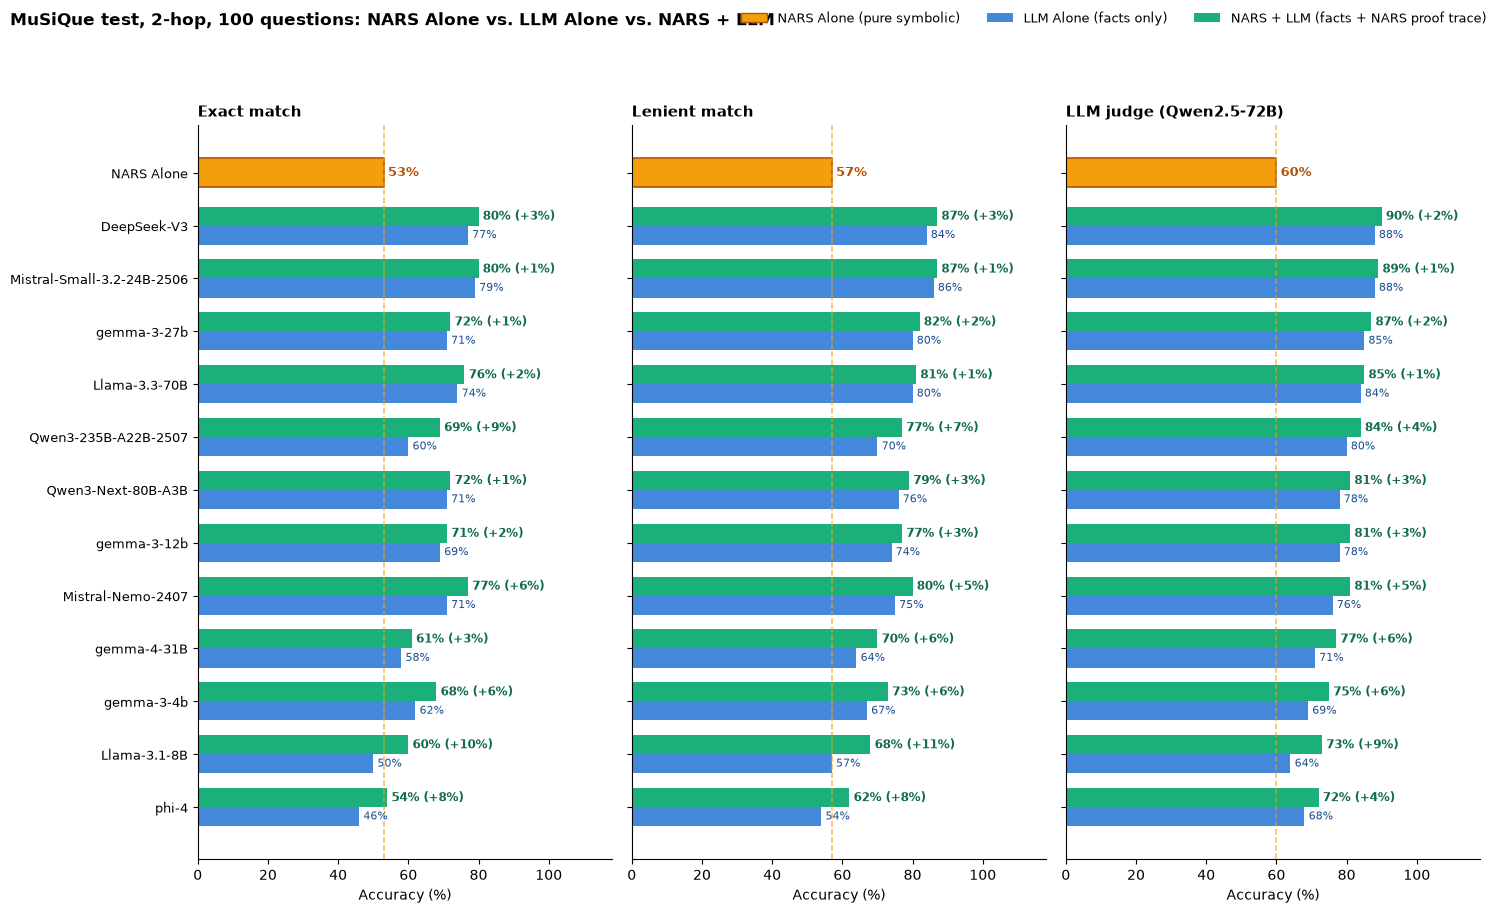

In [5]:
# ── Final report: NARS Alone, LLM Alone, and NARS + LLM on all three metrics ─────────────────────
def load(name):
    path = f"{RUN_DIR}/{name}"
    return {r["index"]: r for r in map(json.loads, open(path))} if os.path.exists(path) else {}


nars_runs = load("nars.jsonl")
baseline_runs = load("baselines.jsonl")
nars_llm_runs = load("nars_llm.jsonl")
assert nars_runs and baseline_runs and nars_llm_runs, (
    f"Run all three cells first (NARS, Baselines, and NARS + LLM) in {RUN_DIR}."
)

common = sorted(set(nars_runs) & set(baseline_runs) & set(nars_llm_runs))
n = len(common)
model_names = [label(m) for m in BASELINES if label(m) in baseline_runs[common[0]]["answers"]]

nars_acc = {m: 100 * sum(nars_runs[i][m] for i in common) / n for m in METRICS}
nars_fq_acc = {m: 100 * sum(nars_runs[i][m] and nars_runs[i].get("from_question", False) for i in common) / n for m in METRICS}
llm_acc = {name: {m: 100 * sum(baseline_runs[i]["answers"][name][m] for i in common) / n for m in METRICS} for name in model_names}
hyb_acc = {name: {m: 100 * sum(nars_llm_runs[i]["answers"][name][m] for i in common) / n for m in METRICS} for name in model_names}

print(f"FINAL REPORT: {DATASET} {SPLIT}, {HOPS}-hop, {n} questions, ONA options {ONA_OPTIONS}")
print(f"NARS Alone:                Exact {nars_acc['exact']:5.1f}% | Lenient {nars_acc['lenient']:5.1f}% | Judge {nars_acc['judge']:5.1f}%")
print(f"NARS (rules from question): Exact {nars_fq_acc['exact']:5.1f}% | Lenient {nars_fq_acc['lenient']:5.1f}% | Judge {nars_fq_acc['judge']:5.1f}%\n")

comp = PrettyTable(["Model", "Exact (LLM -> NARS+LLM)", "Lenient (LLM -> NARS+LLM)", "Judge (LLM -> NARS+LLM)", "Judge Δ"])
order = sorted(model_names, key=lambda name: (hyb_acc[name]["judge"], llm_acc[name]["judge"]), reverse=True)
for name in order:
    row = [name]
    for m in METRICS:
        a, b = llm_acc[name][m], hyb_acc[name][m]
        diff = b - a
        sign = f"+{diff:.1f}%" if diff > 0 else f"{diff:.1f}%"
        row.append(f"{a:5.1f}% -> {b:5.1f}% ({sign})")
    j_diff = hyb_acc[name]["judge"] - llm_acc[name]["judge"]
    row.append(f"+{j_diff:.1f}%" if j_diff > 0 else f"{j_diff:.1f}%")
    comp.add_row(row)
print(comp)

print("\nHOW NARS SYMBOLIC TRACE AFFECTED EACH LLM (judge metric, question counts)")
impact = PrettyTable(["Model", "Both right", "NARS helped (LLM ✗ -> ✓)", "NARS hurt (LLM ✓ -> ✗)", "Neither"])
for name in order:
    b = {i: baseline_runs[i]["answers"][name]["judge"] for i in common}
    h = {i: nars_llm_runs[i]["answers"][name]["judge"] for i in common}
    impact.add_row([
        name,
        sum(b[i] and h[i] for i in common),
        sum(not b[i] and h[i] for i in common),
        sum(b[i] and not h[i] for i in common),
        sum(not b[i] and not h[i] for i in common),
    ])
print(impact)

# ── Chart: 3 panels (Exact, Lenient, Judge) reporting NARS Alone, LLM Alone, and NARS + LLM ──────
plot_order = sorted(model_names, key=lambda name: (hyb_acc[name]["judge"], llm_acc[name]["judge"]))
titles = {"exact": "Exact match", "lenient": "Lenient match", "judge": f"LLM judge ({label(JUDGE_MODEL)})"}
y_pos = np.arange(len(plot_order) + 1)  # +1 at top for standalone NARS Alone
y_labels = [*plot_order, "NARS Alone"]
bar_h = 0.36

fig, axes = plt.subplots(1, 3, figsize=(15, 0.55 * len(y_labels) + 2.0), sharey=True)
for ax, m in zip(axes, METRICS):
    # 1. Paired bars for each LLM: LLM Alone (blue) vs NARS + LLM (green)
    for idx, name in enumerate(plot_order):
        val_llm = llm_acc[name][m]
        val_hyb = hyb_acc[name][m]
        diff = val_hyb - val_llm
        ax.barh(idx - bar_h / 2, val_llm, height=bar_h, color="#2a78d6", alpha=0.88)
        ax.barh(idx + bar_h / 2, val_hyb, height=bar_h, color="#1baf7a")
        ax.text(val_llm + 1.2, idx - bar_h / 2, f"{val_llm:.0f}%", va="center", fontsize=8, color="#1e4f91")
        delta_txt = f" (+{diff:.0f}%)" if diff > 0 else (f" ({diff:.0f}%)" if diff < 0 else "")
        ax.text(val_hyb + 1.2, idx + bar_h / 2, f"{val_hyb:.0f}%{delta_txt}", va="center", fontsize=8.5, fontweight="bold", color="#0f6b4a")

    # 2. Standalone NARS Alone bar + vertical reference line
    nars_y = len(plot_order)
    val_nars = nars_acc[m]
    ax.barh(nars_y, val_nars, height=0.55, color="#f59e0b", edgecolor="#b45309", linewidth=1.2)
    ax.axvline(val_nars, color="#f59e0b", linestyle="--", linewidth=1.1, alpha=0.7)
    ax.text(val_nars + 1.2, nars_y, f"{val_nars:.0f}%", va="center", fontsize=9, fontweight="bold", color="#b45309")

    ax.set_yticks(y_pos)
    ax.set_yticklabels(y_labels, fontsize=9.5)
    ax.set_xlim(0, 118)
    ax.set_title(titles[m], fontsize=11, fontweight="bold", loc="left")
    ax.set_xlabel("Accuracy (%)")
    ax.spines[["top", "right"]].set_visible(False)

legend_handles = [
    Patch(facecolor="#f59e0b", edgecolor="#b45309", label="NARS Alone (pure symbolic)"),
    Patch(facecolor="#2a78d6", alpha=0.88, label="LLM Alone (facts only)"),
    Patch(facecolor="#1baf7a", label="NARS + LLM (facts + NARS proof trace)"),
]
fig.legend(handles=legend_handles, loc="upper right", ncol=3, frameon=False, fontsize=9.5)
fig.suptitle(f"{DATASET} {SPLIT}, {HOPS}-hop, {n} questions: NARS Alone vs. LLM Alone vs. NARS + LLM", x=0.01, y=0.99, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
out_png = f"{RUN_DIR}/report_nars_llm.png"
fig.savefig(out_png, dpi=200)
print(f"\nSaved chart to {out_png}")
plt.show()